# Genetic Ties and EpiLink Compatibility

## Examination of the current percentile convention and a midpoint alternative.

EpiLink compares an observed genetic distance with simulated distances. Its current empirical cumulative distribution counts **all simulated values at or below the observation**. That is a valid CDF. Applying the compatibility transformation to that CDF can, however, give a low score to a very common discrete outcome.

This notebook:

1. Defines the current and midpoint percentile conventions.
2. Demonstrates how tied discrete values affect compatibility scores through illustrative examples.
3. Examines genetic score distributions from EpiLink under both conventions.
4. Shows how the choice propagates to combined genetic–temporal scores.

The midpoint scorer is implemented only for this analysis; it does not modify EpiLink. All examples use synthetic data with baseline parameters.

Run all cells in order from the evaluation repository or its `assets` directory. The notebook prefers a neighboring EpiLink source checkout and otherwise uses the installed package. Figures are saved under `assets`.


In [ ]:
import inspect
import platform
import subprocess
import sys
from pathlib import Path

working_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        parent
        for parent in (working_dir, *working_dir.parents)
        if (parent / "src" / "epilink_evaluation").is_dir()
    ),
    working_dir,
)
source_candidates = [
    PROJECT_ROOT.parent / "epilink" / "src",
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "epilink" / "src",
]
for candidate in source_candidates:
    if (candidate / "epilink" / "__init__.py").is_file():
        sys.path.insert(0, str(candidate.resolve()))
        break

evaluation_source = PROJECT_ROOT / "src"
if evaluation_source.is_dir():
    sys.path.insert(0, str(evaluation_source))
import epilink
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from epilink import EpiLink, InfectiousnessToTransmission, NaturalHistoryParameters
from scipy.stats import percentileofscore

from epilink_evaluation.utils.style import (
    add_panel_labels,
    new_figure,
    save_figure,
    theme,
)

# Apply publication theme
theme(context="paper", font_scale=1.0)

# Color palette (colorblind-safe)
CURRENT = "#C05A32"
MIDPOINT = "#176B87"
MASS = "#748699"
SEED = 12345
MC_SAMPLES = 10_000

model_source = Path(inspect.getfile(EpiLink)).resolve()
try:
    source_revision = subprocess.run(
        ["git", "-C", str(model_source.parent), "rev-parse", "HEAD"],
        capture_output=True,
        text=True,
        check=True,
    ).stdout.strip()
except (OSError, subprocess.CalledProcessError):
    source_revision = "Not available"

provenance = pd.Series(
    {
        "Python": platform.python_version(),
        "EpiLink": epilink.__version__,
        "NumPy": np.__version__,
        "SciPy": scipy.__version__,
        "EpiLink source": str(model_source),
        "Source revision": source_revision,
        "Random seed": SEED,
        "Monte Carlo samples": MC_SAMPLES,
    },
    name="Execution provenance",
).to_frame()
provenance

,Execution provenance
Python,3.14.5
EpiLink,0.1.5
NumPy,2.4.6
SciPy,1.17.1
EpiLink source,/Users/ydnkka/Desktop/PhD Project/Projects/epi...
Source revision,1a113c1c132ff38315bb4cb34125dc1aa3c0a563
Random seed,12345
Monte Carlo samples,10000


In [21]:
print(NaturalHistoryParameters())

NaturalHistoryParameters(incubation_shape=5.807, incubation_scale=0.948, latent_shape=3.38, symptomatic_rate=0.37, symptomatic_shape=1.0, transmission_rate_ratio=2.29, testing_delay_shape=2.0, testing_delay_scale=1.0, substitution_rate=0.001, relaxation=0.33, genome_length=29903)


## 1. Percentile Conventions

For genetic draws $G_1,\ldots,G_N$ and an observed distance $g$, the current implementation uses the right-inclusive empirical CDF:

$$
F_{\mathrm{right}}(g)=\frac{\#\{G_r\leq g\}}{N},\qquad
c(F)=1-2|F-0.5|.
$$

This gives compatibility 1 **only if the empirical percentile is exactly 0.5**. Repeated mutation counts create jumps that can skip 0.5. A median observation need not have $F_{\mathrm{right}}=0.5$.

The alternative considered here places the observation halfway through its tied values:

$$F_{\mathrm{mid}}(g)=\frac{\#\{G_r<g\}+\frac12\#\{G_r=g\}}{N}.$$

This is the average of the strict and right-inclusive percentiles, equivalent to SciPy's `percentileofscore(..., kind="mean") / 100`. Both versions then use the same transformation $c$. They measure percentile centrality, not a probability of transmission.


In [2]:
def empirical_percentiles(draws, observations, convention="right"):
    """Evaluate right-inclusive or midpoint percentiles without changing the draws."""
    draws = np.asarray(draws, dtype=float)
    observations = np.asarray(observations, dtype=float)
    if draws.ndim != 1 or draws.size == 0 or not np.all(np.isfinite(draws)):
        raise ValueError("draws must be a non-empty, finite one-dimensional array")
    if not np.all(np.isfinite(observations)):
        raise ValueError("observations must be finite")
    ordered = np.sort(draws)
    right = np.searchsorted(ordered, observations, side="right")
    if convention == "right":
        return right / draws.size
    if convention == "midpoint":
        left = np.searchsorted(ordered, observations, side="left")
        return (left + right) / (2 * draws.size)
    raise ValueError("convention must be 'right' or 'midpoint'")


def compatibility(percentiles):
    """Transform percentile to compatibility score."""
    return 1 - 2 * np.abs(np.asarray(percentiles, dtype=float) - 0.5)


def score_table(draws, observations=None):
    """Create comparison table for both conventions."""
    draws = np.asarray(draws)
    if observations is None:
        observations = np.unique(draws)
    observations = np.atleast_1d(np.asarray(observations, dtype=float))
    right = empirical_percentiles(draws, observations, "right")
    midpoint = empirical_percentiles(draws, observations, "midpoint")
    return pd.DataFrame(
        {
            "Observed distance": observations,
            "Count equal": [(draws == g).sum() for g in observations],
            "Mass at observation": [(draws == g).mean() for g in observations],
            "F right": right,
            "F midpoint": midpoint,
            "Current score": compatibility(right),
            "Midpoint score": compatibility(midpoint),
        }
    )

## 2. Illustrative Examples

These are deliberately constructed arrays to demonstrate the mathematical behavior:

- **90% zero:** the current percentile at zero is 0.9 and compatibility is 0.2. The midpoint percentile is 0.45 and compatibility is 0.9.
- **All zero:** the current percentile at zero is 1 and compatibility is 0. The midpoint percentile is 0.5 and compatibility is 1.
- **30–40–30:** 30 draws are zero, 40 are one, and 30 are two. The current CDF jumps from 0.3 to 0.7 at one. The median and modal value therefore receives 0.6; the midpoint convention gives it 1.

These are genetic **component** scores. EpiLink subsequently multiplies genetic and temporal components within a scenario, then sums across the selected scenarios.


In [3]:
toy_draws = {
    "90% zero": np.repeat([0, 1], [90, 10]),
    "All zero": np.zeros(100, dtype=int),
    "30–40–30": np.repeat([0, 1, 2], [30, 40, 30]),
}
toy_tables = pd.concat(
    [score_table(draws).assign(Example=name) for name, draws in toy_draws.items()],
    ignore_index=True,
)
toy_tables.set_index(["Example", "Observed distance"]).round(4)

for name, observed, expected_current, expected_midpoint in [
    ("90% zero", 0, 0.2, 0.9),
    ("All zero", 0, 0.0, 1.0),
    ("30–40–30", 1, 0.6, 1.0),
]:
    row = score_table(toy_draws[name], [observed]).iloc[0]
    np.testing.assert_allclose(row["Current score"], expected_current)
    np.testing.assert_allclose(row["Midpoint score"], expected_midpoint)
    np.testing.assert_allclose(
        row["Current score"], EpiLink.compatibility_score(observed, toy_draws[name])[1]
    )
print("Worked examples match the stated scores and EpiLink's current scorer.")

Worked examples match the stated scores and EpiLink's current scorer.


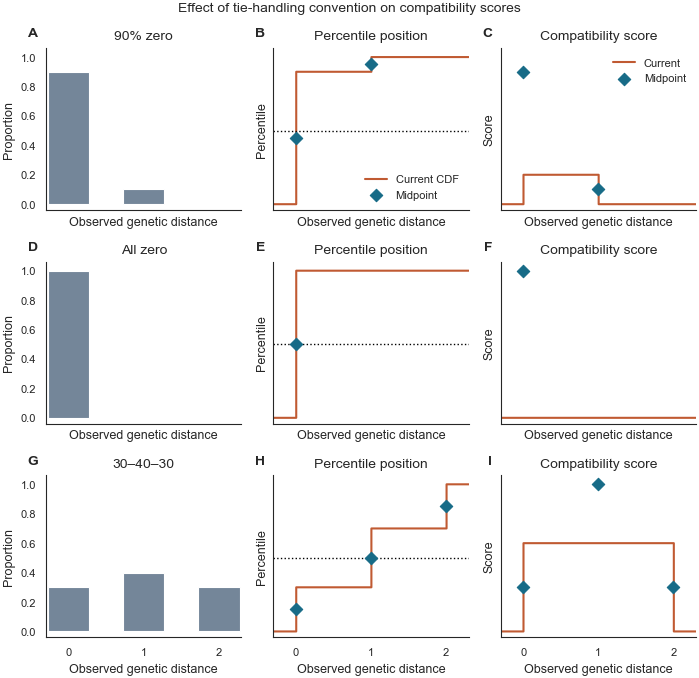

In [4]:
with theme(context="paper"):
    fig, axes = new_figure(
        width="double", nrows=3, ncols=3, height_in=7, sharex=True, sharey=True
    )

    for row, (name, draws) in enumerate(toy_draws.items()):
        support, counts = np.unique(draws, return_counts=True)
        x = np.linspace(-0.3, 2.3, 521)
        current = empirical_percentiles(draws, x, "right")
        table = score_table(draws, support)

        # Mass distribution
        axes[row, 0].bar(support, counts / draws.size, width=0.55, color=MASS)
        axes[row, 0].set_title(f"{name}")
        axes[row, 0].set_ylabel("Proportion")

        # Percentile position
        axes[row, 1].step(
            x, current, where="post", color=CURRENT, label="Current CDF", linewidth=1.5
        )
        axes[row, 1].scatter(
            support,
            table["F midpoint"],
            color=MIDPOINT,
            marker="D",
            s=40,
            zorder=4,
            label="Midpoint" if row == 0 else "",
        )
        axes[row, 1].axhline(0.5, color="black", linestyle=":", linewidth=1)
        axes[row, 1].set_title("Percentile position")
        axes[row, 1].set_ylabel("Percentile")

        # Compatibility score
        axes[row, 2].step(
            x,
            compatibility(current),
            where="post",
            color=CURRENT,
            label="Current",
            linewidth=1.5,
        )
        axes[row, 2].scatter(
            support,
            table["Midpoint score"],
            color=MIDPOINT,
            marker="D",
            s=40,
            zorder=4,
            label="Midpoint" if row == 0 else "",
        )
        axes[row, 2].set_title("Compatibility score")
        axes[row, 2].set_ylabel("Score")

        for ax in axes[row]:
            ax.set(
                xlim=(-0.3, 2.3),
                ylim=(-0.04, 1.06),
                xticks=[0, 1, 2],
                xlabel="Observed genetic distance",
            )

    axes[0, 1].legend(fontsize=8, loc="lower right")
    axes[0, 2].legend(fontsize=8, loc="upper right")
    fig.suptitle(
        "Effect of tie-handling convention on compatibility scores", fontsize=10
    )
    add_panel_labels(axes)
    plt.tight_layout()
    plt.show()

    # Save figure
    save_figure(
        fig,
        PROJECT_ROOT / "assets/supplementary_toy_examples",
        width="double",
        save_pdf=True,
        save_png=True,
    )

**Reading the plots:** the orange steps use the current CDF convention. Blue diamonds replace the value only at an observation that equals one or more draws. Between tied values, the two percentile conventions agree.

### How the zero mass controls the score at zero

For a non-negative distribution, let $p_0$ be the fraction of draws equal to zero. Then

$$c_{\mathrm{right}}(0)=1-2|p_0-0.5|,\qquad c_{\mathrm{mid}}(0)=p_0.$$

Once more than half the draws are zero, the current score at zero **decreases as zero becomes more common**. The midpoint rule does **not** uniformly raise scores. At zero, its score exceeds the current score only when more than two thirds of the draws are zero.


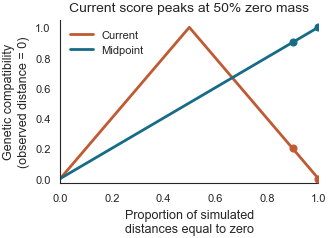

In [8]:
p_zero = np.linspace(0, 1, 201)
with theme(context="paper"):
    fig, ax = new_figure(width="single", height_in=2.6)
    ax.plot(p_zero, compatibility(p_zero), color=CURRENT, linewidth=2, label="Current")
    ax.plot(
        p_zero, compatibility(p_zero / 2), color=MIDPOINT, linewidth=2, label="Midpoint"
    )
    ax.scatter([0.9, 1], [0.2, 0], color=CURRENT, zorder=3)
    ax.scatter([0.9, 1], [0.9, 1], color=MIDPOINT, zorder=3)
    ax.set(
        xlabel="Proportion of simulated\ndistances equal to zero",
        ylabel="Genetic compatibility\n(observed distance = 0)",
        title="Current score peaks at 50% zero mass",
        xlim=(0, 1),
        ylim=(-0.03, 1.05),
    )
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

    save_figure(
        fig,
        PROJECT_ROOT / "assets/supplementary_zero_mass_effect",
        width="single",
        save_pdf=True,
        save_png=True,
    )

## 3. Verification

The following checks compare the notebook implementation with EpiLink's scalar API and SciPy's independent percentile implementation.

Three qualifications matter:

- Ties **can**, but need not, prevent the current score reaching 1. A 50–50 distribution gives the lower value a current score of 1.
- The midpoint convention also need not reach 1. With masses 10%, 30%, and 60%, none of the midpoint percentiles is exactly 0.5.
- Neither score is a probability mass or likelihood. With half the draws at zero and half at two, an unobserved value of one has percentile 0.5 and scores 1 under both rules.

For observations unequal to every draw, the two conventions are identical. This matters for **non-integer scaled TN93 distances** in the Boston application: the midpoint change acts at exact matches, such as zero or an exactly integer count.


In [9]:
test_cases = {
    **toy_draws,
    "50–50": np.repeat([0, 1], [50, 50]),
    "10–30–60": np.repeat([0, 1, 2], [10, 30, 60]),
    "Gap in support": np.repeat([0, 2], [50, 50]),
}
observations = np.array([-1, 0, 0.25, 0.5, 1, 1.5, 2, 3])

# Verification checks
for name, draws in test_cases.items():
    right = empirical_percentiles(draws, observations, "right")
    midpoint = empirical_percentiles(draws, observations, "midpoint")

    # Verify against SciPy
    np.testing.assert_allclose(
        right, percentileofscore(draws, observations, kind="weak") / 100
    )
    np.testing.assert_allclose(
        midpoint, percentileofscore(draws, observations, kind="mean") / 100
    )

    # Verify against EpiLink
    np.testing.assert_allclose(
        right, [EpiLink.percentile_score(g, draws) for g in observations]
    )
    np.testing.assert_allclose(
        compatibility(right),
        [EpiLink.compatibility_score(g, draws)[1] for g in observations],
    )

    # Non-matches should be identical
    nonmatches = ~np.isin(observations, draws)
    np.testing.assert_allclose(right[nonmatches], midpoint[nonmatches])

    # Scores should be in valid range
    assert np.all((compatibility(midpoint) >= 0) & (compatibility(midpoint) <= 1))

print("Verification passed: agreement with EpiLink and SciPy; valid score ranges.")

Verification passed: agreement with EpiLink and SciPy; valid score ranges.


## 4. EpiLink Genetic Distributions

We retrieve the genetic distributions used by EpiLink for direct transmission [ad(0)] and co-primary infection from the same source [ca(0,0)]. Parameters follow the Chapter 3 baseline. The genetic arrays are **marginal distributions within a scenario**.


In [10]:
incubation_mean = 5.505036
incubation_cv = 0.4149770576
parameters = NaturalHistoryParameters(
    incubation_shape=1 / incubation_cv**2,
    incubation_scale=incubation_mean * incubation_cv**2,
    latent_shape=3.38,
    symptomatic_rate=0.37,
    symptomatic_shape=1.0,
    transmission_rate_ratio=2.29,
    testing_delay_shape=1.0,
    testing_delay_scale=1.0,
    substitution_rate=0.001,
    relaxation=0.33,
    genome_length=29_903,
)
profile = InfectiousnessToTransmission(parameters=parameters, rng_seed=SEED)
model = EpiLink(
    transmission_profile=profile,
    maximum_depth=0,
    mc_samples=MC_SAMPLES,
    target=["ad(0)", "ca(0,0)"],
    mutation_process="stochastic",
)

# Extract genetic draws
genetic_draws = {
    label: model.draws_by_scenario[label]["genetic_draws"].copy()
    for label in model.target_labels
}

# Display parameters
pd.Series(parameters.to_dict(), name="Parameter value").to_frame().round(3)

,Parameter value
incubation_shape,5.807
incubation_scale,0.948
latent_shape,3.380
symptomatic_rate,0.370
symptomatic_shape,1.000
transmission_rate_ratio,2.290
testing_delay_shape,1.000
testing_delay_scale,1.000
substitution_rate,0.001
relaxation,0.330


In [11]:
# Summary statistics
distribution_summaries = []
for label, draws in genetic_draws.items():
    table = score_table(draws)
    modes = table.loc[
        table["Count equal"] == table["Count equal"].max(), "Observed distance"
    ].tolist()
    zero = score_table(draws, [0]).iloc[0]
    distribution_summaries.append(
        {
            "Scenario": label,
            "Mean distance": draws.mean(),
            "Median distance": np.median(draws),
            "Mode(s)": str(modes),
            "Zero proportion": np.mean(draws == 0),
            "Current score at zero": zero["Current score"],
            "Midpoint score at zero": zero["Midpoint score"],
            "Best current score": table["Current score"].max(),
            "Best midpoint score": table["Midpoint score"].max(),
        }
    )
distribution_summary = pd.DataFrame(distribution_summaries).set_index("Scenario")
distribution_summary.round(4)

,Mean distance,Median distance,Mode(s),Zero proportion,Current score at zero,Midpoint score at zero,Best current score,Best midpoint score
Scenario,,,,,,,,
ad(0),0.5202,0.0,[0.0],0.6415,0.717,0.6415,0.7170,0.6415
"ca(0,0)",2.1654,2.0,[1.0],0.1535,0.307,0.1535,0.8208,0.9477


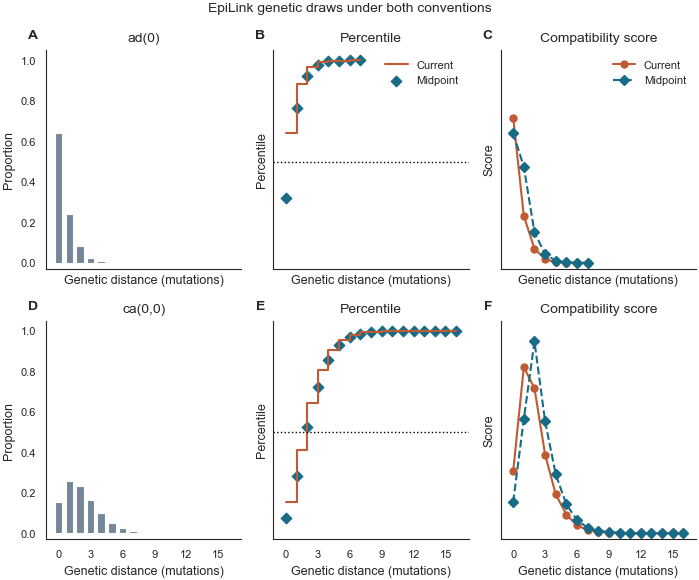

ad(0): 64.1% zero draws; score at zero 0.717 (current) vs 0.641 (midpoint).
ca(0,0): 15.3% zero draws; score at zero 0.307 (current) vs 0.153 (midpoint).


In [14]:
with theme(context="paper"):
    fig, axes = new_figure(
        width="double", nrows=2, ncols=3, height_in=6, sharex=True, sharey=True
    )

    for row, (label, draws) in enumerate(genetic_draws.items()):
        support = np.arange(int(draws.max()) + 1)
        table = score_table(draws, support)

        # Mass distribution
        axes[row, 0].bar(support, table["Mass at observation"], color=MASS, width=0.7)
        axes[row, 0].set_title(f"{label}")
        axes[row, 0].set_ylabel("Proportion")

        # Percentile
        axes[row, 1].step(
            support,
            table["F right"],
            where="post",
            color=CURRENT,
            label="Current",
            linewidth=1.5,
        )
        axes[row, 1].scatter(
            support,
            table["F midpoint"],
            color=MIDPOINT,
            marker="D",
            s=30,
            label="Midpoint" if row == 0 else "",
        )
        axes[row, 1].axhline(0.5, color="black", linestyle=":", linewidth=1)
        axes[row, 1].set_title("Percentile")
        axes[row, 1].set_ylabel("Percentile")

        # Compatibility score
        axes[row, 2].plot(
            support,
            table["Current score"],
            "o-",
            color=CURRENT,
            label="Current",
            linewidth=1.5,
        )
        axes[row, 2].plot(
            support,
            table["Midpoint score"],
            "D--",
            color=MIDPOINT,
            label="Midpoint" if row == 0 else "",
        )
        axes[row, 2].set_title("Compatibility score")
        axes[row, 2].set_ylabel("Score")

        for ax in axes[row]:
            ax.set(
                xlabel="Genetic distance (mutations)",
                ylim=(-0.03, 1.05),
            )
            ax.xaxis.set_major_locator(
                matplotlib.ticker.MaxNLocator(integer=True, nbins=8)
            )

    axes[0, 1].legend(fontsize=8)
    axes[0, 2].legend(fontsize=8)
    fig.suptitle("EpiLink genetic draws under both conventions", fontsize=10)
    add_panel_labels(axes)
    plt.tight_layout()
    plt.show()

    save_figure(
        fig,
        PROJECT_ROOT / "assets/supplementary_epilink_distributions",
        width="double",
        save_pdf=True,
        save_png=True,
    )

# Print summary
for label, row in distribution_summary.iterrows():
    print(
        f"{label}: {row['Zero proportion']:.1%} zero draws; "
        f"score at zero {row['Current score at zero']:.3f} (current) vs "
        f"{row['Midpoint score at zero']:.3f} (midpoint)."
    )

### Deterministic Genetic Inference

Deterministic genetic inference uses expected mutation counts rather than Poisson draws. That does not guarantee a tie-free distribution. In the implementation, ancestor–descendant branch lengths are clipped at zero, giving exactly zero expected mutations.


In [15]:
deterministic_model = EpiLink(
    transmission_profile=InfectiousnessToTransmission(
        parameters=parameters, rng_seed=SEED
    ),
    maximum_depth=0,
    mc_samples=MC_SAMPLES,
    target=["ad(0)", "ca(0,0)"],
    mutation_process="deterministic",
)
deterministic_rows = []
for label, draws in deterministic_model.draws_by_scenario.items():
    values = draws["genetic_draws"]
    zero = score_table(values, [0]).iloc[0]
    deterministic_rows.append(
        {
            "Scenario": label,
            "Unique values": np.unique(values).size,
            "Zero branch proportion": np.mean(draws["branch_draws"] == 0),
            "Zero genetic proportion": np.mean(values == 0),
            "Current score at zero": zero["Current score"],
            "Midpoint score at zero": zero["Midpoint score"],
        }
    )
pd.DataFrame(deterministic_rows).set_index("Scenario").round(4)

,Unique values,Zero branch proportion,Zero genetic proportion,Current score at zero,Midpoint score at zero
Scenario,,,,,
ad(0),9110,0.0891,0.0891,0.1782,0.0891
"ca(0,0)",10000,0.0000,0.0000,0.0000,0.0000


## 5. Combined Score Propagation

EpiLink multiplies the temporal and genetic components within each scenario and then sums across the target set:

$$
C(t,g)=\sum_{s\in\{\mathrm{ad}(0),\mathrm{ca}(0,0)\}}
c(F_{T,s}(t))\,c(F_{G,s}(g)).
$$

To isolate the genetic tie convention, we change **only the genetic percentile**, keeping all other components fixed. The grid contains hypothetical observed pairs to illustrate where scores could change.


In [16]:
def score_with_genetic_convention(
    model, sample_time_difference, genetic_distance, convention
):
    """Score pairs using specified genetic convention."""
    times, genetics = np.broadcast_arrays(
        np.asarray(sample_time_difference, dtype=float),
        np.asarray(genetic_distance, dtype=float),
    )
    result = np.zeros(times.shape, dtype=float)
    for label in model.target_labels:
        draws = model.draws_by_scenario[label]
        temporal_score = compatibility(
            empirical_percentiles(draws["time_draws"], times, "right")
        )
        genetic_score = compatibility(
            empirical_percentiles(draws["genetic_draws"], genetics, convention)
        )
        result += temporal_score * genetic_score
    return result


# Create grid
time_values = np.arange(0, 22, dtype=float)
genetic_values = np.arange(0, 9, dtype=float)
times = time_values[:, None]
genetics = genetic_values[None, :]
current_grid = score_with_genetic_convention(model, times, genetics, "right")
midpoint_grid = score_with_genetic_convention(model, times, genetics, "midpoint")

# Verify against EpiLink API
np.testing.assert_allclose(
    current_grid, model.score_target(times, genetics), atol=1e-12
)

# Verify non-integer distances are unchanged
fractional_genetics = np.arange(0.25, 8.5, 0.5)[None, :]
np.testing.assert_allclose(
    score_with_genetic_convention(model, times, fractional_genetics, "right"),
    score_with_genetic_convention(model, times, fractional_genetics, "midpoint"),
)

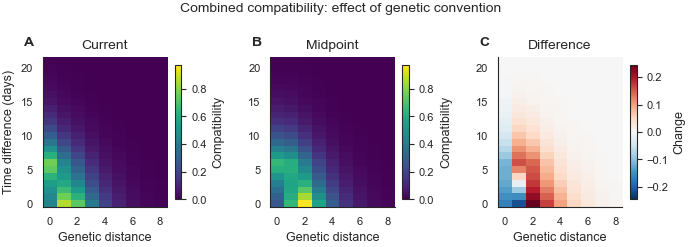

,Illustrative grid
Grid points,198.0000
Fraction changed,1.0000
Max absolute change,0.2455
Mean absolute change,0.0323


In [19]:
with theme(context="paper"):
    fig, axes = new_figure(width="double", ncols=3, height_in=2.6)
    shared_max = max(current_grid.max(), midpoint_grid.max())
    extent = (-0.5, 8.5, -0.5, 21.5)

    # Current
    im = axes[0].imshow(
        current_grid,
        origin="lower",
        aspect="auto",
        extent=extent,
        vmin=0,
        vmax=shared_max,
        cmap="viridis",
    )
    axes[0].set_title("Current")
    axes[0].set_xlabel("Genetic distance")
    axes[0].set_ylabel("Time difference (days)")

    # Midpoint
    axes[1].imshow(
        midpoint_grid,
        origin="lower",
        aspect="auto",
        extent=extent,
        vmin=0,
        vmax=shared_max,
        cmap="viridis",
    )
    axes[1].set_title("Midpoint")
    axes[1].set_xlabel("Genetic distance")

    # Difference
    difference = midpoint_grid - current_grid
    limit = max(np.abs(difference).max(), 1e-12)
    im_diff = axes[2].imshow(
        difference,
        origin="lower",
        aspect="auto",
        extent=extent,
        vmin=-limit,
        vmax=limit,
        cmap="RdBu_r",
    )
    axes[2].set_title("Difference")
    axes[2].set_xlabel("Genetic distance")

    # Colorbars
    cbar1 = fig.colorbar(im, ax=axes[0], shrink=0.9, label="Compatibility")
    cbar2 = fig.colorbar(im, ax=axes[1], shrink=0.9, label="Compatibility")
    cbar3 = fig.colorbar(im_diff, ax=axes[2], shrink=0.9, label="Change")

    for ax in axes:
        ax.grid(False)
        ax.set_xticks([0, 2, 4, 6, 8])

    fig.suptitle("Combined compatibility: effect of genetic convention", fontsize=10)
    add_panel_labels(axes)
    plt.tight_layout()
    plt.show()

    save_figure(
        fig,
        PROJECT_ROOT / "assets/supplementary_combined_score_grid",
        width="double",
        save_pdf=True,
        save_png=True,
    )

# Summary statistics
grid_summary = pd.Series(
    {
        "Grid points": current_grid.size,
        "Fraction changed": np.mean(np.abs(difference) > 1e-12),
        "Max absolute change": np.abs(difference).max(),
        "Mean absolute change": np.abs(difference).mean(),
    },
    name="Illustrative grid",
)
grid_summary.to_frame().round(4)

## 6. Interpretation

**What this analysis establishes:**

- The current code implements a right-inclusive empirical CDF correctly. The concern is the interpretation of its transformed value as compatibility with discrete outcomes.
- Large tied masses can depress the score of a common or even universal observation.
- Midpoint percentiles remove the specific asymmetry illustrated by the examples. They remain a design choice and do not turn the score into a likelihood or calibrated probability.
- The impact depends on the scenario, parameters, and observed distances. Differences do not automatically disappear with more Monte Carlo draws.
- A tied value can affect combined weights, while a value strictly between integer draws is unchanged.

**What remains to be evaluated:**

Before changing the package, compare both conventions using the same cached draws and observed pairs in the existing synthetic benchmark. First hold the target set, temporal rule, sparsification threshold, and clustering resolution fixed, so the comparison isolates genetic tie handling. Report pairwise average precision, changes in retained edges and weights, and cluster precision, recall, and F1 against the existing reference memberships. Then assess sensitivity across parameter settings, random seeds, and resolutions.

The midpoint score is a **candidate for sensitivity analysis**, not an established improvement in epidemiological accuracy. This analysis intentionally leaves the production method and existing benchmark results unchanged.


## 7. Alternative Methods for Future Development

These are candidates for future sensitivity analysis. Each method is **deterministic conditional on the simulated draws**. Let $g$ be the observed genetic distance and let $h(f)=1-2|f-1/2|$ be the compatibility transformation.

### 1. Include ties in both tails

$$
c_{\mathrm{inclusive}}(g)
=\min\left\{1,\;2\min\left[P(G\leq g),P(G\geq g)\right]\right\}.
$$

This includes equality in both tails and corresponds to the conventional twice-the-smaller-tail construction for discrete tests (Fay, 2010).

### 2. Analytically average randomised compatibility

Let $a=P(G<g)$ and $b=P(G=g)$. Randomised tie handling places the percentile at $a+Ub$, where $U\sim\mathrm{Uniform}(0,1)$. Integrating over all possible positions gives:

$$
c_{\mathrm{average}}(g)
=\int_0^1\left[1-2\left|a+ub-\tfrac12\right|\right]\,du.
$$

**Averaging scores differs from transforming the average percentile.** When every draw and the observation are zero, the averaged score is $0.5$, whereas the midpoint score is $1$.

### 3. Order outcomes by probability mass

For discrete draws, define $p(k)=P(G=k)$ and calculate

$$
c_{\mathrm{mass}}(g)
=\sum_{k:\,p(k)\leq p(g)}p(k).
$$

This sums the probabilities of outcomes no more probable than the observation. A most probable outcome receives one. It changes the interpretation towards how common an outcome is, rather than where it lies within the distribution.

### Illustrative Comparison

| Method                    | 90% zero; observe 0 | All zero; observe 0 |
| ------------------------- | ------------------: | ------------------: |
| Current right-inclusive   |                0.20 |                   0 |
| Midpoint                  |                0.90 |                   1 |
| Both tails include ties   |                1.00 |                   1 |
| Analytically averaged     |               ≈0.54 |                 0.5 |
| Probability-mass ordering |                1.00 |                   1 |

**Reference:** Fay, M. P. (2010). Two-sided Exact Tests and Matching Confidence Intervals for Discrete Data. _The R Journal_, 2(1), 53–58.
